# 02 – Exploratory Data Analysis

What drives default in the Lending Club loans, and what would a lender do about it?

**Population.** The model-ready table: 36-month, Individual loans issued 2013 to 2015 with a final outcome. To keep the final test set untouched, every feature chart uses the **train and validation** loans only (issued up to June 2015). One question needs loans outside that population: the 36 vs 60 month comparison, which reads the raw data (resolved loans only).

Rates are shares of loans that ended as Charged Off or Default. Nothing here is causal: it describes who defaulted, not why.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from scipy.stats import gaussian_kde

from credit_risk.config import FIGURES_DIR, LOANS_PROCESSED_PARQUET, TARGET
from credit_risk.data import audit

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, RED, GRAY = "#2a78d6", "#eb6834", "#e34948", "#f0efec"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pct = PercentFormatter(1.0, decimals=0)


def label_bars(ax, bars, labels, fontsize=8):
    """Value labels at the bar ends, on a surface-coloured patch so a reference line never cuts through them."""
    for text in ax.bar_label(bars, labels=labels, padding=3, color=INK2, fontsize=fontsize):
        text.set_bbox({"fc": SURFACE, "ec": "none", "pad": 1})


def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


def rate_table(frame, column, min_loans=500):
    """Loans and default rate per value of `column`; values with fewer than `min_loans` loans are dropped."""
    t = frame.groupby(column, observed=True)[TARGET].agg(loans="size", rate="mean")
    return t[t["loans"] >= min_loans]


df = pd.read_parquet(LOANS_PROCESSED_PARQUET)
eda = df[df["split"] != "test"].copy()
overall = eda[TARGET].mean()
print(f"{len(eda):,} loans issued {eda.issue_d.min():%b %Y} to {eda.issue_d.max():%b %Y}; default rate {overall:.1%}")

383,782 loans issued Jan 2013 to Jun 2015; default rate 13.8%


## 1. Default rate by Lending Club grade

Grade is Lending Club's own risk assessment, so it is not a feature of the headline model. It shows how much risk the data holds.

,loans,rate
grade,,
A,83015,0.0536
B,129519,0.1081
C,102416,0.1732
D,50404,0.2284
E,14923,0.2780
F,3216,0.3134


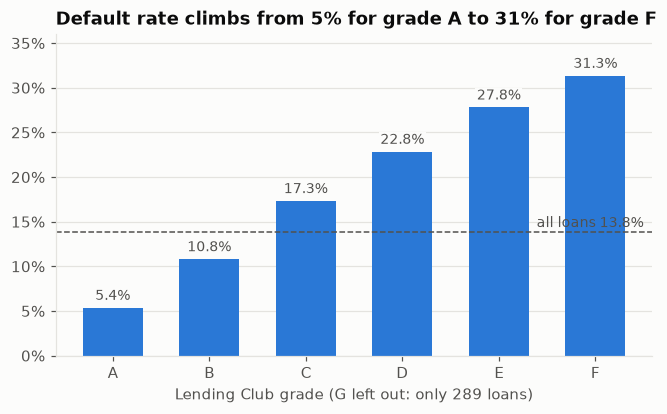

In [2]:
g = rate_table(eda, "grade")
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(g.index, g["rate"], color=BLUE, width=0.62)
label_bars(ax, bars, [f"{v:.1%}" for v in g["rate"]], fontsize=9)
ax.axhline(overall, color=INK2, lw=1, ls="--")
ax.text(len(g) - 0.5, overall + 0.006, f"all loans {overall:.1%}", ha="right", color=INK2, fontsize=9)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, g["rate"].max() * 1.15)
ax.set_title("Default rate climbs from 5% for grade A to 31% for grade F")
ax.set_xlabel("Lending Club grade (G left out: only 289 loans)")
save(fig, "default_rate_by_grade")
g.assign(rate=g["rate"].round(4))

## 2. 36 vs 60 month loans (raw data, matured years only)

Only 2010 to 2013 are shown: in those years every loan of both terms has a final outcome, so the two rates compare fairly. Later 60-month loans are still running and would look better than they are.

term_months,36,60,ratio
issue_year,,,
2010,0.1092,0.2239,2.0500
2011,0.1063,0.2360,2.2196
2012,0.1358,0.2770,2.0395
2013,0.1233,0.2515,2.0402


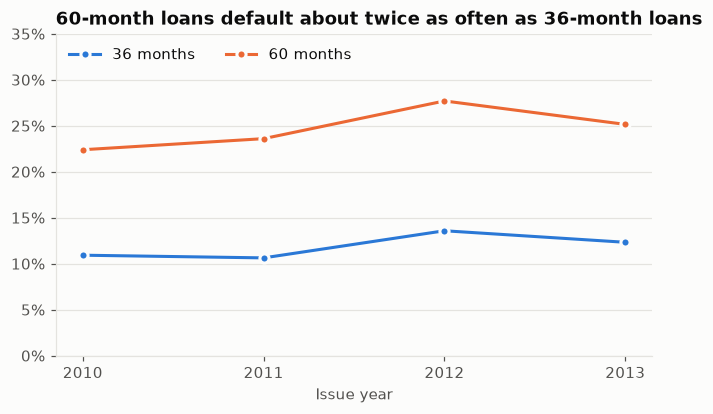

In [3]:
con = audit.open_raw_loans()
audit.create_audit_view(con)
term = con.execute("""
    SELECT issue_year, term_months, count(*) AS loans, avg(is_default) AS rate
    FROM loans_audit
    WHERE outcome <> 'unresolved' AND trim(application_type) = 'Individual' AND issue_year BETWEEN 2010 AND 2013
    GROUP BY 1, 2 ORDER BY 1, 2
""").df()
wide = term.pivot(index="issue_year", columns="term_months", values="rate")
fig, ax = plt.subplots(figsize=(7, 3.8))
for months, color in ((36, BLUE), (60, ORANGE)):
    ax.plot(wide.index, wide[months], color=color, lw=2, marker="o", ms=6, mfc=color, mec=SURFACE, mew=2, label=f"{months} months")
ax.set_xticks(wide.index)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.35)
ax.legend(loc="upper left", ncols=2)
ax.set_xlabel("Issue year")
ax.set_title("60-month loans default about twice as often as 36-month loans")
save(fig, "default_rate_by_term")
out = wide.copy()
out["ratio"] = out[60] / out[36]
out.round(4)

## 3. Default over time (vintage analysis) and unemployment

Top: default rate of the loans issued each month. Bottom: the average state unemployment rate for the month before issue. They are separate charts rather than one chart with two scales.

,loans,default_rate,unemployment,int_rate
year,,,,
2013,100422,0.1233,7.5832,13.3670
2014,162570,0.1373,6.3803,12.4654
2015,120790,0.1512,5.6283,11.5079


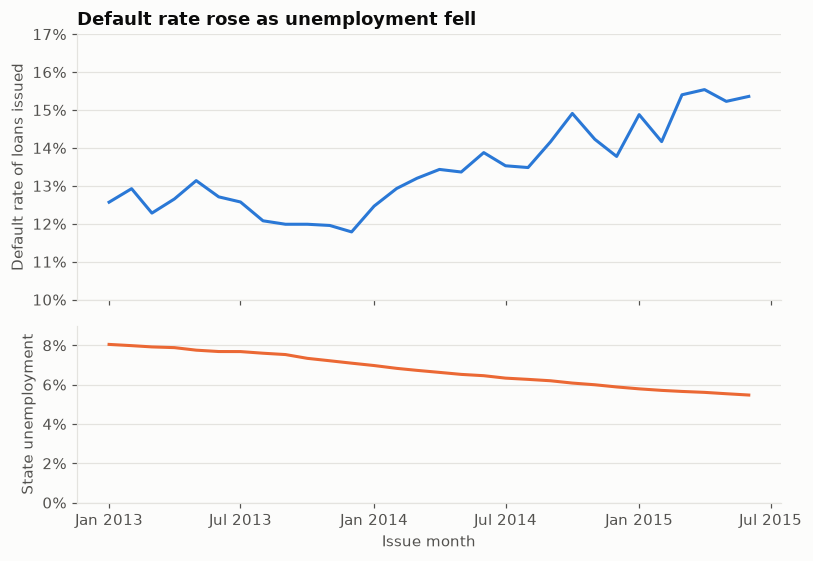

In [4]:
monthly = eda.groupby("issue_d").agg(rate=(TARGET, "mean"), unemployment=("state_unemployment_rate", "mean"), loans=("id", "size"))
fig, (a, b) = plt.subplots(2, 1, figsize=(7.5, 5.2), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
a.plot(monthly.index, monthly["rate"], color=BLUE, lw=2)
a.yaxis.set_major_formatter(pct)
a.set_ylim(0.10, 0.17)
a.set_title("Default rate rose as unemployment fell")
b.plot(monthly.index, monthly["unemployment"], color=ORANGE, lw=2)
b.set_ylim(0, 9)
b.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
b.set_xlabel("Issue month")
b.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
b.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
a.set_ylabel("Default rate of loans issued")
b.set_ylabel("State unemployment")
fig.tight_layout()
save(fig, "default_rate_vs_unemployment")
eda["year"] = eda.issue_d.dt.year
eda.groupby("year").agg(loans=("id", "size"), default_rate=(TARGET, "mean"), unemployment=("state_unemployment_rate", "mean"), int_rate=("int_rate", "mean")).round(4)

In [5]:
# Is the rise only a change in grade mix? Share of loans and default rate by grade and issue year:
print("Share of loans by grade:")
print(eda.groupby("year").grade.value_counts(normalize=True).unstack().round(3).to_string())
print("\nDefault rate by grade:")
print(eda.groupby(["year", "grade"])[TARGET].mean().unstack().round(3).to_string())

Share of loans by grade:
grade      A      B      C      D      E      F      G
year                                                  
2013    0.17  0.401  0.246  0.144  0.032  0.006    0.0
2014   0.217  0.329  0.271  0.126  0.043  0.012  0.001
2015   0.254  0.296  0.279  0.127  0.038  0.005  0.001

Default rate by grade:
grade      A      B      C      D      E      F      G
year                                                  
2013   0.046  0.098  0.153  0.204  0.233  0.268  0.267
2014   0.054  0.107  0.172  0.222  0.270  0.295  0.363
2015   0.058  0.121  0.190  0.260  0.321  0.416  0.347


Within every grade, loans issued later defaulted more, even though unemployment fell (7.6% in 2013 to 5.6% in 2015). So the rise is not a weaker economy and not only a shift towards riskier grades: lending standards or the borrower mix changed. This is why the split is by time, and why train (13.2%), validation (15.1%) and test (14.7%) have different default rates.

In [6]:
# Within a state and month, does a higher unemployment rate go with more defaults?
sm = eda.groupby(["addr_state", "issue_d"]).agg(rate=(TARGET, "mean"), loans=("id", "size"), u=("state_unemployment_rate", "first"))
sm = sm[sm["loans"] >= 50]
print(f"{len(sm):,} state-months with 50+ loans; correlation of default rate with unemployment: {sm['rate'].corr(sm['u']):.3f}")
bands = pd.cut(eda.state_unemployment_rate, [0, 4.5, 5.5, 6.5, 7.5, 8.5, 20])
eda.groupby(bands, observed=True)[TARGET].agg(loans="size", rate="mean").round(4)

1,111 state-months with 50+ loans; correlation of default rate with unemployment: 0.002


,loans,rate
state_unemployment_rate,,
"(0.0, 4.5]",28378,0.1379
"(4.5, 5.5]",58079,0.1401
"(5.5, 6.5]",127054,0.1431
"(6.5, 7.5]",96508,0.1370
"(7.5, 8.5]",47001,0.1306
"(8.5, 20.0]",26762,0.1260


## 4. Loan purpose, home ownership, verification, employment

,loans,rate
purpose,,
debt_consolidation,224375,0.1441
credit_card,94695,0.1160
home_improvement,20724,0.1216
other,18968,0.1630
major_purchase,6764,0.1316
medical,3803,0.1709
small_business,3703,0.2295
car,3566,0.1147
moving,2565,0.1981


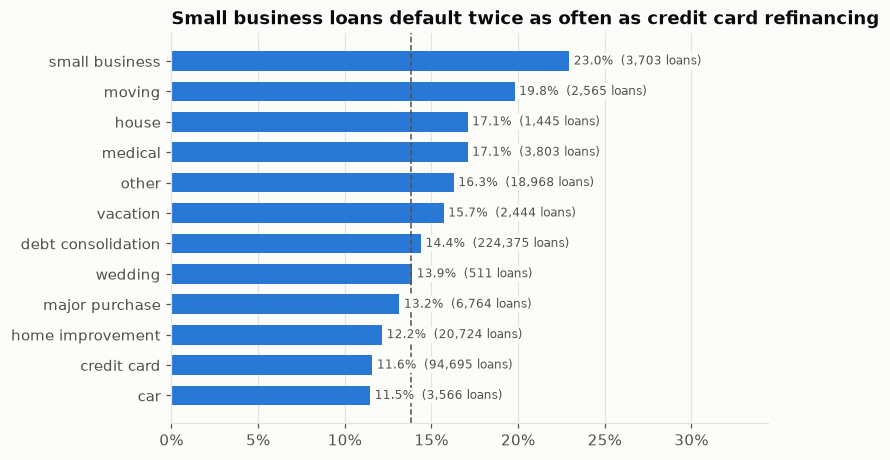

In [7]:
p = rate_table(eda, "purpose").sort_values("rate")
fig, ax = plt.subplots(figsize=(7, 4.6))
bars = ax.barh(p.index.str.replace("_", " "), p["rate"], color=BLUE, height=0.65)
label_bars(ax, bars, [f"{v:.1%}  ({n:,} loans)" for v, n in zip(p["rate"], p["loans"])])
ax.axvline(overall, color=INK2, lw=1, ls="--")
ax.xaxis.set_major_formatter(pct)
ax.set_xlim(0, p["rate"].max() * 1.5)
ax.grid(axis="y", visible=False)
ax.grid(axis="x")
ax.set_title("Small business loans default twice as often as credit card refinancing")
save(fig, "default_rate_by_purpose")
p.assign(rate=p["rate"].round(4)).sort_values("loans", ascending=False)

emp_length not given: 5.8% of loans, default rate 20.2% vs 13.4% for the rest
Within grade, not given vs given:
grade          A      B      C      D      E      F      G
not_given  0.088  0.163  0.230  0.279  0.316  0.388  0.345
given      0.052  0.105  0.169  0.224  0.274  0.305  0.354


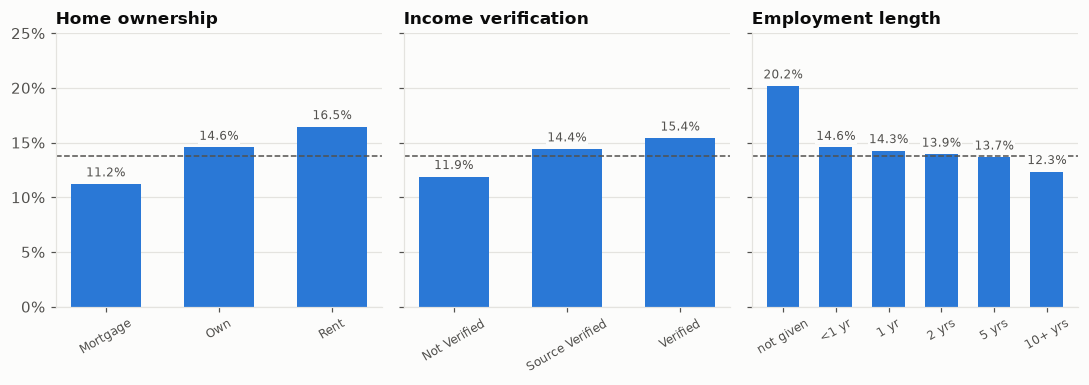

In [8]:
def emp_label(v):
    if pd.isna(v):
        return "not given"
    return "<1 yr" if v == 0 else ("10+ yrs" if v == 10 else (f"{int(v)} yr" if v == 1 else f"{int(v)} yrs"))


fig, axes = plt.subplots(1, 3, figsize=(10, 3.6), sharey=True)
for ax, col, title in zip(axes, ["home_ownership", "verification_status", None], ["Home ownership", "Income verification", "Employment length"]):
    if col:
        t = rate_table(eda, col).sort_values("rate")
        labels = t.index.str.replace("_", " ").str.title()
    else:
        t = rate_table(eda.assign(emp=eda.emp_length.map(emp_label)), "emp").loc[["not given", "<1 yr", "1 yr", "2 yrs", "5 yrs", "10+ yrs"]]
        labels = t.index
    bars = ax.bar(labels, t["rate"], color=BLUE, width=0.62)
    label_bars(ax, bars, [f"{v:.1%}" for v in t["rate"]])
    ax.axhline(overall, color=INK2, lw=1, ls="--")
    ax.set_title(title, fontsize=11)
    ax.tick_params(axis="x", labelrotation=30, labelsize=8)
axes[0].yaxis.set_major_formatter(pct)
axes[0].set_ylim(0, 0.25)
fig.tight_layout()
save(fig, "default_rate_by_borrower_profile")
no_emp = eda.emp_length.isna()
print(f"emp_length not given: {no_emp.mean():.1%} of loans, default rate {eda[no_emp][TARGET].mean():.1%} vs {eda[~no_emp][TARGET].mean():.1%} for the rest")
print("Within grade, not given vs given:")
print(pd.DataFrame({"not_given": eda[no_emp].groupby("grade")[TARGET].mean(), "given": eda[~no_emp].groupby("grade")[TARGET].mean()}).round(3).T.to_string())

## 5. State (states with 500+ loans)

46 states with 500+ loans; lowest NH 9.2%, highest MS 18.4%


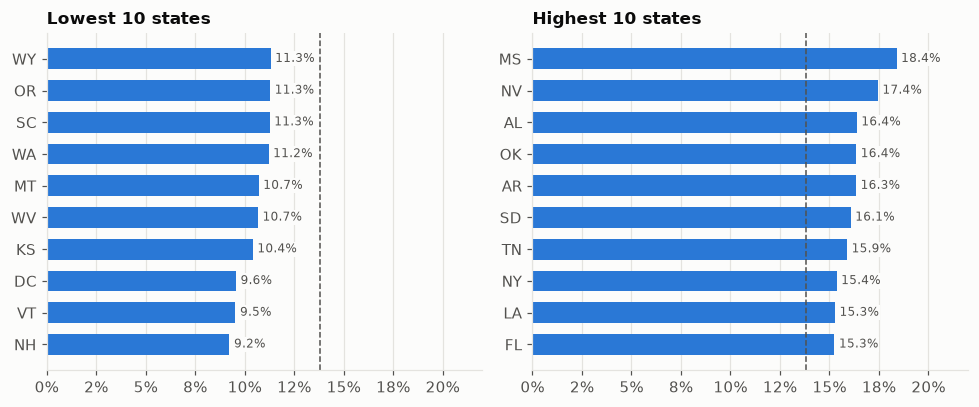

In [9]:
s = rate_table(eda, "addr_state").sort_values("rate")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharex=True)
for ax, part, title in ((axes[0], s.head(10), "Lowest 10 states"), (axes[1], s.tail(10), "Highest 10 states")):
    bars = ax.barh(part.index, part["rate"], color=BLUE, height=0.65)
    label_bars(ax, bars, [f"{v:.1%}" for v in part["rate"]])
    ax.axvline(overall, color=INK2, lw=1, ls="--")
    ax.set_title(title, fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x")
    ax.xaxis.set_major_formatter(pct)
axes[0].set_xlim(0, 0.22)
fig.tight_layout()
save(fig, "default_rate_by_state")
print(f"{len(s)} states with 500+ loans; lowest {s.rate.idxmin()} {s.rate.min():.1%}, highest {s.rate.idxmax()} {s.rate.max():.1%}")

## 6. Default rate across the range of each numeric feature

Each panel splits the loans into ten equal-sized groups (deciles) by the feature and shows the default rate in each group. The x-axis shows the median value of the lowest, middle and highest group.

,feature,lowest decile,highest decile
0,int_rate,0.040,0.253
1,fico_mid,0.186,0.059
2,annual_inc,0.201,0.093
3,dti,0.105,0.194
4,revol_util,0.106,0.160
5,credit_history_years,0.173,0.117


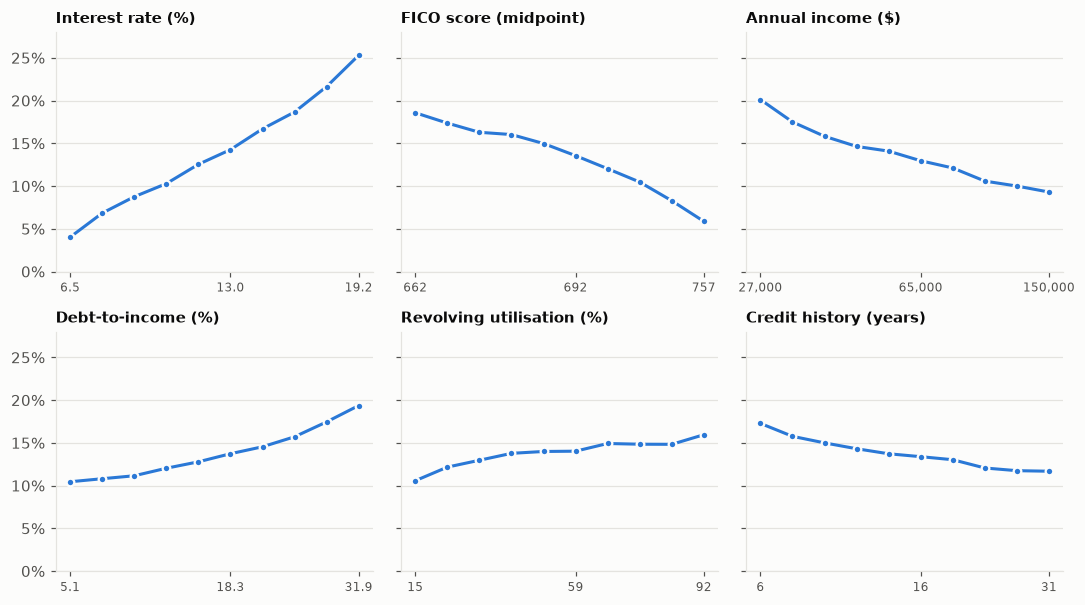

In [10]:
panels = [("int_rate", "Interest rate (%)", "{:.1f}"), ("fico_mid", "FICO score (midpoint)", "{:.0f}"), ("annual_inc", "Annual income ($)", "{:,.0f}"),
          ("dti", "Debt-to-income (%)", "{:.1f}"), ("revol_util", "Revolving utilisation (%)", "{:.0f}"), ("credit_history_years", "Credit history (years)", "{:.0f}")]
fig, axes = plt.subplots(2, 3, figsize=(10, 5.6), sharey=True)
rows = []
for ax, (col, label, fmt) in zip(axes.ravel(), panels):
    d = eda.groupby(pd.qcut(eda[col], 10, duplicates="drop"), observed=True).agg(rate=(TARGET, "mean"), mid=(col, "median"))
    ax.plot(range(len(d)), d["rate"], color=BLUE, lw=2, marker="o", ms=5, mfc=BLUE, mec=SURFACE, mew=1.5)
    ticks = [0, len(d) // 2, len(d) - 1]
    ax.set_xticks(ticks)
    ax.set_xticklabels([fmt.format(d["mid"].iloc[i]) for i in ticks], fontsize=8)
    ax.set_title(label, fontsize=10)
    ax.yaxis.set_major_formatter(pct)
    ax.set_ylim(0, 0.28)
    rows.append((col, d["rate"].iloc[0], d["rate"].iloc[-1]))
fig.tight_layout()
save(fig, "default_rate_by_decile")
pd.DataFrame(rows, columns=["feature", "lowest decile", "highest decile"]).round(3)

## 7. Defaulters vs non-defaulters

,annual_inc,dti,int_rate,fico_mid,loan_amnt
is_default,,,,,
fully paid,62000.0,16.82,11.99,687.0,10200.0
defaulted,54000.0,19.12,13.99,682.0,10000.0


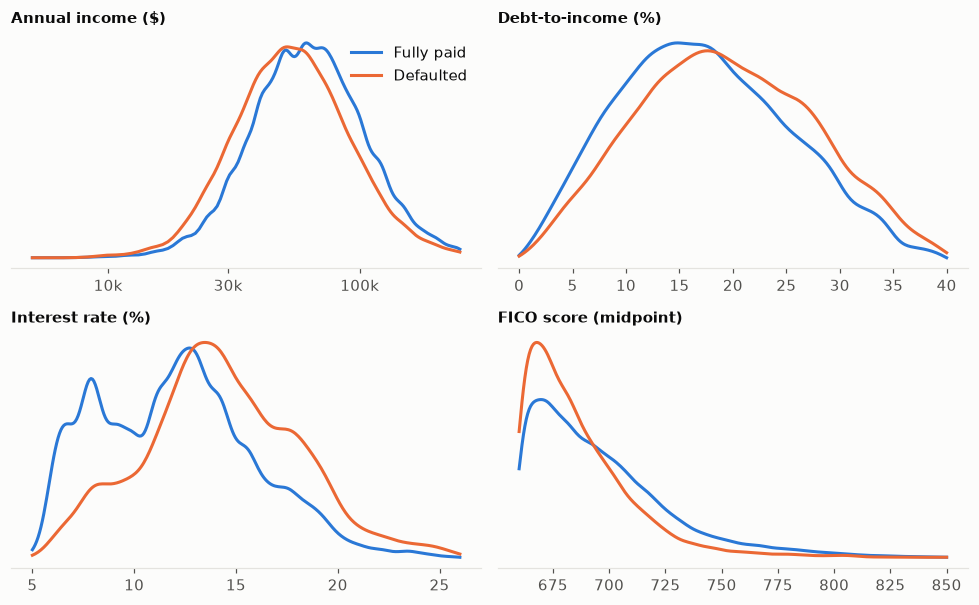

In [11]:
panels = [("annual_inc", "Annual income ($)", (5_000, 250_000), True), ("dti", "Debt-to-income (%)", (0, 40), False),
          ("int_rate", "Interest rate (%)", (5, 26), False), ("fico_mid", "FICO score (midpoint)", (660, 850), False)]
sample = eda.sample(60_000, random_state=42)
fig, axes = plt.subplots(2, 2, figsize=(9, 5.6))
for ax, (col, label, (lo, hi), use_log) in zip(axes.ravel(), panels):
    grid = np.linspace(lo, hi, 300)
    for flag, color, name in ((0, BLUE, "Fully paid"), (1, ORANGE, "Defaulted")):
        v = sample.loc[sample[TARGET] == flag, col].dropna()
        v = v[v.between(lo, hi)]
        v = np.log(v) if use_log else v
        dens = gaussian_kde(v)(np.log(grid) if use_log else grid)
        ax.plot(grid, dens, color=color, lw=2, label=name)
    if use_log:
        ax.set_xscale("log")
        ax.set_xticks([10_000, 30_000, 100_000])
        ax.set_xticklabels(["10k", "30k", "100k"])
        ax.minorticks_off()
    ax.set_yticks([])
    ax.set_title(label, fontsize=10)
    ax.grid(visible=False)
    ax.spines["left"].set_visible(False)
axes[0, 0].legend(loc="upper right")
fig.tight_layout()
save(fig, "distributions_defaulters_vs_paid")
eda.groupby(TARGET)[["annual_inc", "dti", "int_rate", "fico_mid", "loan_amnt"]].median().rename(index={0: "fully paid", 1: "defaulted"})

## 8. Correlation between numeric features

Spearman correlation (rank-based, so outliers and skew matter less). The first row shows each feature against default.

Feature pairs with |correlation| above 0.9 (candidates to drop one of each):


correlation
fico_range_high      fico_mid                            1.000
fico_range_low       fico_mid                            1.000
                     fico_range_high                     1.000
open_acc             num_sats                            0.999
loan_amnt            installment                         0.994
loan_to_income       instalment_to_monthly_income        0.993
num_actv_rev_tl      num_rev_tl_bal_gt_0                 0.990
tot_cur_bal          tot_hi_cred_lim                     0.986
mo_sin_old_rev_tl_op credit_history_years                0.924

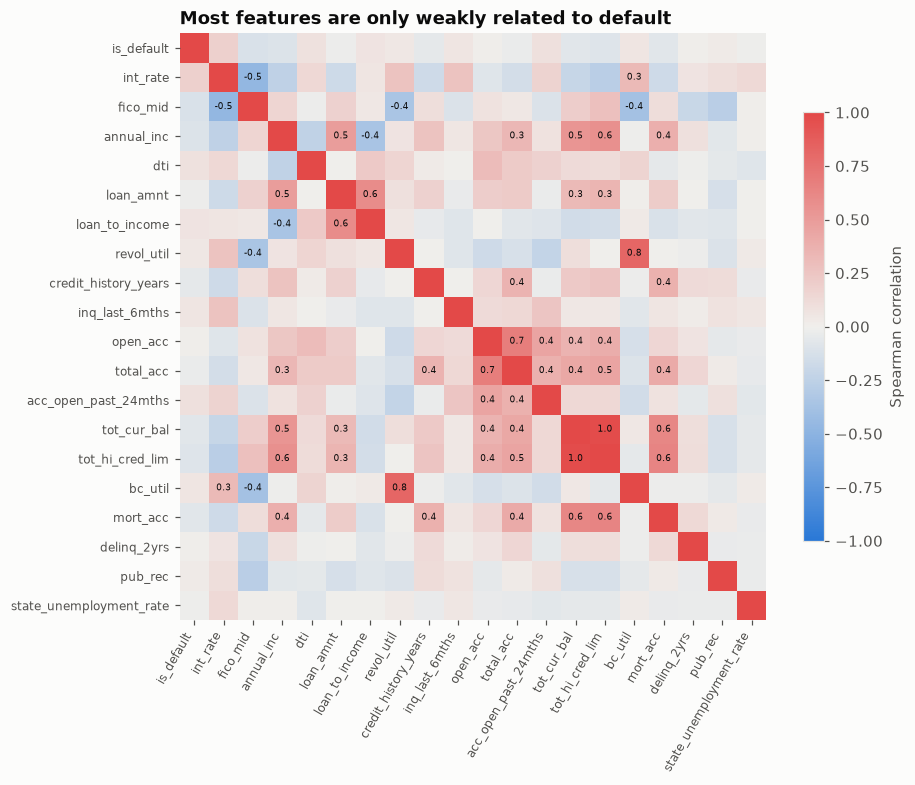

In [12]:
cols = [TARGET, "int_rate", "fico_mid", "annual_inc", "dti", "loan_amnt", "loan_to_income", "revol_util", "credit_history_years", "inq_last_6mths",
        "open_acc", "total_acc", "acc_open_past_24mths", "tot_cur_bal", "tot_hi_cred_lim", "bc_util", "mort_acc", "delinq_2yrs", "pub_rec", "state_unemployment_rate"]
corr = eda[cols].corr(method="spearman")
cmap = LinearSegmentedColormap.from_list("div", [BLUE, GRAY, RED])
fig, ax = plt.subplots(figsize=(8.5, 7.2))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(cols)))
ax.set_yticklabels(cols, fontsize=8)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        if abs(corr.iloc[i, j]) >= 0.3 and i != j:
            ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6, color=INK)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman correlation")
ax.set_title("Most features are only weakly related to default")
fig.tight_layout()
save(fig, "correlation_matrix")
num = eda.select_dtypes("number").drop(columns=["id", "issue_month", "year"])
cm = num.drop(columns=[TARGET]).corr()
pairs = cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack()
print("Feature pairs with |correlation| above 0.9 (candidates to drop one of each):")
pairs[pairs.abs() > 0.9].sort_values(ascending=False).round(3).to_frame("correlation")

In [13]:
# Strongest single relationships with default (Spearman, all numeric columns)
r = num.corr(method="spearman")[TARGET].drop(TARGET).dropna()
r.reindex(r.abs().sort_values(ascending=False).index).head(10).round(3).to_frame("spearman with default")

,spearman with default
int_rate,0.185
fico_range_low,-0.116
fico_range_high,-0.116
fico_mid,-0.116
annual_inc,-0.095
tot_hi_cred_lim,-0.091
bc_open_to_buy,-0.091
acc_open_past_24mths,0.091
total_bc_limit,-0.088
avg_cur_bal,-0.087


## 9. Skewness of the numeric features

None of the features is normally distributed, and many are lopsided. Skewness measures this: 0 is symmetric, and about 1 or more is clearly skewed (a long tail of large values). It is measured on the **training loans only**, because any transform in the model pipeline is fitted on training data.

The last column shows the skewness after a log transform (`log1p`, which is log(1 + x) so zeros are allowed). Tree models (XGBoost, LightGBM) do not care about skew. The logistic regression baseline does, so this table decides which columns to transform in week 5.

In [14]:
from scipy.stats import skew

train = df[df["split"] == "train"]
candidates = train.select_dtypes("number").drop(columns=["id", TARGET, "issue_month"])
rows = []
for col in candidates.columns:
    v = candidates[col].dropna()
    if v.nunique() < 3:
        continue
    rows.append({
        "feature": col,
        "skew": skew(v),
        "skew_after_log1p": skew(np.log1p(v)) if (v >= 0).all() else np.nan,
        "share_zero": (v == 0).mean(),
        "distinct_values": v.nunique(),
    })
skew_table = pd.DataFrame(rows).set_index("feature")
skew_table = skew_table.reindex(skew_table["skew"].abs().sort_values(ascending=False).index)
bands = pd.cut(skew_table["skew"].abs(), [0, 0.5, 1, 2, 5, np.inf], right=False,
               labels=["below 0.5 (roughly symmetric)", "0.5 to 1", "1 to 2", "2 to 5", "5 and above"])
print(f"{len(skew_table)} numeric features in the training loans")
print(bands.value_counts().sort_index().to_string())
skew_table.round(2)

61 numeric features in the training loans
skew
below 0.5 (roughly symmetric)    12
0.5 to 1                          5
1 to 2                           21
2 to 5                           17
5 and above                       6


,skew,skew_after_log1p,share_zero,distinct_values
feature,,,,
num_tl_120dpd_2m,38.33,36.55,1.00,3
delinq_amnt,25.57,19.22,1.00,284
tot_coll_amt,12.91,2.42,0.86,5172
tax_liens,9.95,7.14,0.97,6
num_tl_90g_dpd_24m,7.71,4.81,0.94,7
...,...,...,...,...
revol_util,-0.17,-2.35,0.00,1023
mths_since_recent_bc_dlq,0.15,-1.23,0.00,134
mths_since_last_major_derog,0.12,-1.33,0.00,146


**Reading the table**

- Roughly symmetric: `dti`, `int_rate`, `revol_util`, `loan_to_income` and `emp_length`. They are bounded or piled up at one end, so not bell-shaped, but they are not heavily skewed.
- Money amounts (`annual_inc`, `revol_bal`, `tot_cur_bal`, `total_rev_hi_lim` and similar) are strongly right-skewed, and `log1p` brings most of them close to symmetric.
- Counts of bad events (`delinq_2yrs`, `pub_rec`, `tax_liens`, `delinq_amnt`, `num_tl_120dpd_2m`) are mostly zero with a few large values. A log transform barely helps them, because the problem is the pile of zeros (see `share_zero`). For the logistic regression, band them (none / one / more than one) or cap them lower.
- The outlier caps from the cleaning step were already applied, and skewness is still high, so the caps do not make the features symmetric. They only remove the most extreme tail.

## What this means for the model

- Ranking power is spread across many weak signals. No feature has a rank correlation with default above 0.19, and the strongest, interest rate, is Lending Club's own assessment. Without it, FICO is the strongest (-0.12), so expect a much lower AUC than grade and rate would give.
- Several features are near duplicates (the FICO triple, `open_acc` and `num_sats`, `loan_amnt` and `installment`, and others listed above). Drop one of each pair for the logistic regression.
- Many features are strongly skewed (section 9). That does not matter for gradient boosting, but the logistic regression baseline needs a `log1p` on the money columns and banding on the event counts, fitted on the training set only.
- Missing `emp_length` is informative, so keep it as missing rather than filling it in.
- Unemployment adds almost nothing in this window, so do not expect it to be a top driver.
- Default rates drift upward within every grade across 2013 to 2015, so a model trained on older loans may under-predict on newer ones. Check calibration on the test set.